# Part 2. Where does it rain, and where does the state declare emergency?
**Group 6 - rainy season January 1 to May 31, 2023**

Part 1 showed that the rainiest departments were not the ones with the most emergency
declarations. Here we put both variables on a map of Peru to see **where** that mismatch happens.

In [1]:
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

BASE = Path.cwd()
if (BASE / "assignment_3").is_dir():
    BASE = BASE / "assignment_3"
DATOS = BASE / "datos"
FUENTE = "Source: PCM emergency decrees via gob.pe + Open-Meteo (Jan-May 2023); boundaries: INEI districts (session 7)."

## 1. Load our table with `ubigeo` as text

The department ubigeo is a 2-digit code (`'01'` = Amazonas). If it is read as a number,
`'01'` becomes `1` and the join with the map breaks, so we force `dtype={"ubigeo": str}`.

In [2]:
df = pd.read_csv(DATOS / "dataset.csv", dtype={"ubigeo": str})
print(df.shape)
print("ubigeo dtype:", df["ubigeo"].dtype, "| example:", repr(df["ubigeo"].iloc[0]))
df[["ubigeo", "departamento", "declaratorias", "lluvia_total_mm", "dias_lluvia_fuerte"]].head()

(25, 9)
ubigeo dtype: str | example: '01'


,ubigeo,departamento,declaratorias,lluvia_total_mm,dias_lluvia_fuerte
0,01,Amazonas,3,414.6,3
1,02,Áncash,6,1145.8,9
2,03,Apurímac,1,726.2,3
3,04,Arequipa,4,362.0,1
4,05,Ayacucho,5,498.4,2


## 2. Load the official boundaries and build departments

We use the district GeoJSON from session 7 (`fetch_data.py 07-mapas`, INEI boundaries).
Each district ubigeo has 6 digits and **its first 2 digits are the department code**,
so we cut them with `.str[:2]` and dissolve the 1,874 districts into 25 departments.

In [3]:
distritos = gpd.read_file(DATOS / "distritos_peru.geojson")
print(distritos.shape, "| CRS:", distritos.crs)
print("ubigeo dtype:", distritos["ubigeo"].dtype, "| example:", repr(distritos["ubigeo"].iloc[0]))
distritos.head(3)

(1874, 5) | CRS: EPSG:4326
ubigeo dtype: str | example: '060504'


,ubigeo,departamento,provincia,distrito,geometry
0,060504,CAJAMARCA,CONTUMAZA,GUZMANGO,"POLYGON ((-78.91578 -7.32085, -78.90743 -7.328..."
1,061105,CAJAMARCA,SAN MIGUEL,EL PRADO,"POLYGON ((-79.01679 -6.96945, -79.00984 -6.974..."
2,061109,CAJAMARCA,SAN MIGUEL,NIEPOS,"POLYGON ((-79.21909 -6.85169, -79.20812 -6.853..."


In [4]:
distritos["ubigeo_dep"] = distritos["ubigeo"].str[:2]

columnas = ["ubigeo_dep", "departamento", "geometry"]
departamentos = distritos[columnas].dissolve(by="ubigeo_dep", as_index=False)
departamentos = departamentos.rename(columns={"ubigeo_dep": "ubigeo", "departamento": "departamento_mapa"})
print(departamentos.shape)
departamentos.head()

(25, 3)


,ubigeo,geometry,departamento_mapa
0,01,"POLYGON ((-78.03886 -6.73038, -78.03732 -6.725...",AMAZONAS
1,02,"POLYGON ((-77.7205 -10.3222, -77.72629 -10.324...",ANCASH
2,03,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5...",APURIMAC
3,04,"POLYGON ((-72.77421 -16.62733, -72.79896 -16.6...",AREQUIPA
4,05,"POLYGON ((-74.50523 -15.15687, -74.51267 -15.1...",AYACUCHO


### Closing the gaps between districts

District borders do not fit perfectly, so the dissolve leaves thousands of tiny holes
(they would show up as white specks and make the files heavier). We close them by growing each
department 100 m and shrinking it back. Buffers need metres, so we first project to UTM zone 18S
(`EPSG:32718`) and then return to latitude/longitude (`EPSG:4326`).

In [5]:
import shapely

huecos_antes = shapely.get_num_interior_rings(shapely.get_parts(departamentos.geometry)).sum()

en_metros = departamentos.to_crs(32718)
en_metros["geometry"] = en_metros.buffer(100).buffer(-100)
departamentos = en_metros.to_crs(4326)

huecos_despues = shapely.get_num_interior_rings(shapely.get_parts(departamentos.geometry)).sum()
print("Holes before:", huecos_antes, "| after:", huecos_despues)
print(f"Area of Peru: {en_metros.area.sum() / 1e6:,.0f} km2 (official: 1,285,216 km2)")

Holes before: 13494 | after: 23
Area of Peru: 1,288,505 km2 (official: 1,285,216 km2)


## 3. Check the join **before** merging (report of non-matches)

Both sides must have the ubigeo written the same way: text, 2 digits, leading zero.

In [6]:
en_tabla = set(df["ubigeo"])
en_mapa = set(departamentos["ubigeo"])

print("Matched:", len(en_tabla & en_mapa), "of", len(en_tabla), "rows in our table")
print("In the table but NOT in the map:", sorted(en_tabla - en_mapa))
print("In the map but NOT in the table:", sorted(en_mapa - en_tabla))

Matched: 25 of 25 rows in our table
In the table but NOT in the map: []
In the map but NOT in the table: []


### Why text and not numbers (or names)

The cell below repeats the check with the two classic mistakes, to show what we avoided:
reading ubigeo as a number, and joining by department name.

In [7]:
# Mistake 1: reading ubigeo as a number eats the leading zero ('01' -> 1 -> '1').
df_numero = pd.read_csv(DATOS / "dataset.csv")
ubigeo_numero = set(df_numero["ubigeo"].astype(str))
print("ubigeo read as number -> matches:", len(ubigeo_numero & en_mapa), "of 25")
print("   lost:", sorted(ubigeo_numero - en_mapa))

# Mistake 2: joining by name fails on accents ('ÁNCASH' vs 'ANCASH').
nombres_tabla = set(df["departamento"].str.upper())
nombres_mapa = set(departamentos["departamento_mapa"])
print("join by name -> matches:", len(nombres_tabla & nombres_mapa), "of 25")
print("   lost:", sorted(nombres_tabla - nombres_mapa))

ubigeo read as number -> matches: 16 of 25
   lost: ['1', '2', '3', '4', '5', '6', '7', '8', '9']
join by name -> matches: 20 of 25
   lost: ['APURÍMAC', 'HUÁNUCO', 'JUNÍN', 'SAN MARTÍN', 'ÁNCASH']


### Now the merge

`how="left"` **from the map**, so no department disappears from the drawing.
`indicator=True` adds a `_merge` column that tells us, row by row, whether it matched.

In [8]:
mapa = departamentos.merge(df, on="ubigeo", how="left", indicator=True)
print(mapa["_merge"].value_counts())

no_cruzaron = mapa[mapa["_merge"] != "both"]
print("\nDepartments without data:", len(no_cruzaron))
no_cruzaron[["ubigeo", "departamento_mapa"]]

_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64

Departments without data: 0


,ubigeo,departamento_mapa


Totals must be the same before and after the merge; if they are not, the map lies.

In [9]:
for columna in ["declaratorias", "prorrogas", "lluvia_total_mm", "dias_lluvia_fuerte"]:
    print(f"{columna:20s} table: {df[columna].sum():8.1f} | map: {mapa[columna].sum():8.1f}")

declaratorias        table:     73.0 | map:     73.0
prorrogas            table:      6.0 | map:      6.0
lluvia_total_mm      table:  16063.7 | map:  16063.7
dias_lluvia_fuerte   table:    151.0 | map:    151.0


## 4. Static choropleths by quantiles (GeoPandas)

With only 25 departments and a few extreme values (Lima with 7 declarations, Loreto with
1,605 mm), a continuous scale would paint almost everything the same colour.
`scheme="quantiles", k=4` splits the departments into 4 groups of similar size.

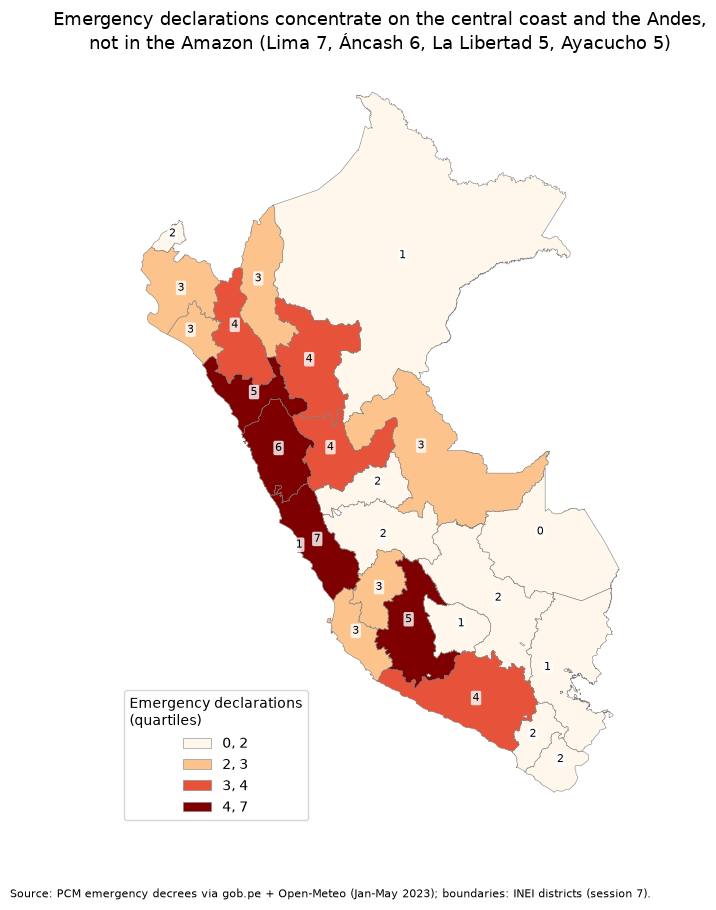

In [10]:
fig, ax = plt.subplots(figsize=(8, 10))
mapa.plot(
    column="declaratorias", cmap="OrRd", scheme="quantiles", k=4,
    edgecolor="grey", linewidth=0.4, legend=True, ax=ax,
    legend_kwds={"loc": "lower left", "title": "Emergency declarations\n(quartiles)", "fmt": "{:.0f}"},
)
for _, fila in mapa.iterrows():
    punto = fila["geometry"].representative_point()
    ax.annotate(str(fila["declaratorias"]), (punto.x, punto.y), ha="center", fontsize=8,
                bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.8})

ax.set_title("Emergency declarations concentrate on the central coast and the Andes,\n"
             "not in the Amazon (Lima 7, Áncash 6, La Libertad 5, Ayacucho 5)", fontsize=13)
ax.set_axis_off()
fig.text(0.05, 0.04, FUENTE, fontsize=8)
plt.show()

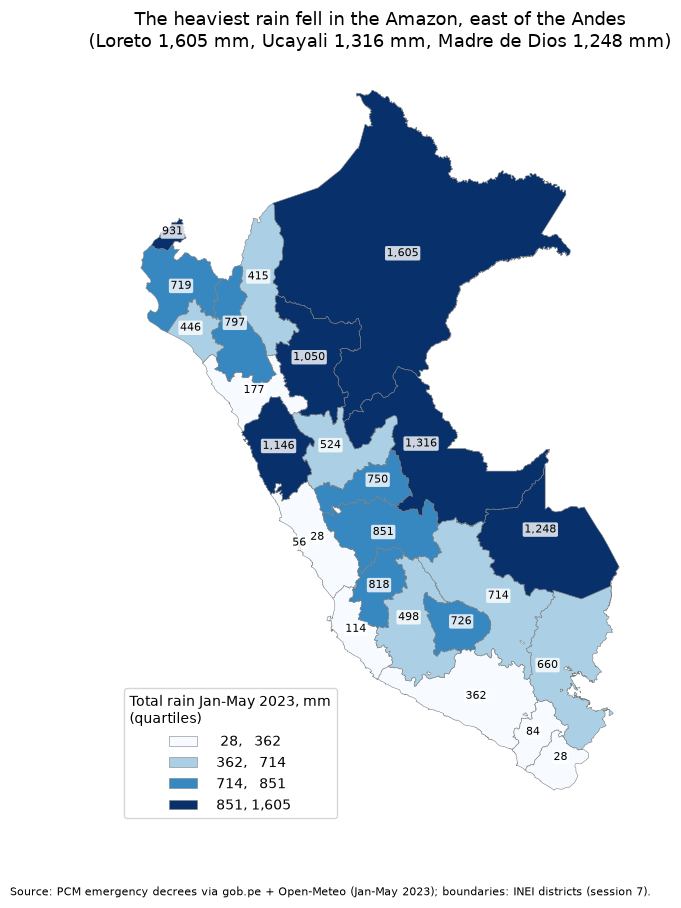

In [11]:
fig, ax = plt.subplots(figsize=(8, 10))
mapa.plot(
    column="lluvia_total_mm", cmap="Blues", scheme="quantiles", k=4,
    edgecolor="grey", linewidth=0.4, legend=True, ax=ax,
    legend_kwds={"loc": "lower left", "title": "Total rain Jan-May 2023, mm\n(quartiles)", "fmt": "{:,.0f}"},
)
for _, fila in mapa.iterrows():
    punto = fila["geometry"].representative_point()
    ax.annotate(f"{fila['lluvia_total_mm']:,.0f}", (punto.x, punto.y), ha="center", fontsize=8,
                bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.8})

ax.set_title("The heaviest rain fell in the Amazon, east of the Andes\n"
             "(Loreto 1,605 mm, Ucayali 1,316 mm, Madre de Dios 1,248 mm)", fontsize=13)
ax.set_axis_off()
fig.text(0.05, 0.04, FUENTE, fontsize=8)
plt.show()

**Quick check:** the darkest classes must match the extremes of the table (cell below):
Lima, Áncash, Ayacucho and La Libertad lead declarations; Loreto, Ucayali and Madre de Dios lead rain.

In [12]:
print(mapa.nlargest(4, "declaratorias")[["departamento", "declaratorias"]].to_string(index=False))
print()
print(mapa.nlargest(4, "lluvia_total_mm")[["departamento", "lluvia_total_mm"]].to_string(index=False))

departamento  declaratorias
        Lima              7
      Áncash              6
    Ayacucho              5
 La Libertad              5

 departamento  lluvia_total_mm
       Loreto           1604.6
      Ucayali           1316.0
Madre de Dios           1248.4
       Áncash           1145.8


## 5. Interactive map (Folium): Choropleth + Tooltip

The colour is the number of emergency declarations; hovering a department shows all its values.
On top, a second layer draws a circle at each departmental capital whose size is the rain measured
there, so both variables can be compared on the same map (layers can be switched on/off at the top right).

*The Folium map is not saved with output (it weighs several MB): run the cell to see it.*

In [13]:
# Simplifying the borders (~1 km) makes the web map much lighter without changing how it looks.
mapa_web = mapa.drop(columns="_merge").copy()
mapa_web["geometry"] = mapa_web.simplify(0.01)

print("Quartiles:", list(mapa_web["declaratorias"].quantile([0.25, 0.5, 0.75])))

# Folium closes the classes on the left ([2, 3) instead of (2, 3]), so with the quartiles 2, 3, 4
# a department with 4 declarations would jump to the top class. Cutting between whole numbers
# keeps the same 4 classes as the static map: 0-2, 3, 4 and 5-7 declarations.
cortes = [0, 2.5, 3.5, 4.5, 7]

Quartiles: [2.0, 3.0, 4.0]


In [14]:
# OpenStreetMap tiles: the CARTO basemap used in session 7 now asks for an API key.
m = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="OpenStreetMap")

folium.Choropleth(
    geo_data=mapa_web,
    data=mapa_web,
    columns=["ubigeo", "declaratorias"],
    key_on="feature.properties.ubigeo",
    fill_color="OrRd", fill_opacity=0.75, line_opacity=0.4,
    bins=cortes,
    legend_name="Emergency declarations, Jan-May 2023 (quartiles)",
    name="Emergency declarations",
).add_to(m)

folium.GeoJson(
    mapa_web,
    name="Tooltip",
    style_function=lambda x: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["departamento", "ubigeo", "declaratorias", "prorrogas", "lluvia_total_mm", "dias_lluvia_fuerte"],
        aliases=["Department:", "Ubigeo:", "Emergency declarations:", "Extensions:",
                 "Total rain (mm):", "Days with rain >= 20 mm:"],
    ),
    control=False,
).add_to(m)

lluvia = folium.FeatureGroup(name="Rain at the capital (circle size)")
for _, fila in df.iterrows():
    folium.CircleMarker(
        location=[fila["latitud"], fila["longitud"]],
        radius=fila["lluvia_total_mm"] ** 0.5 / 2,
        color="#1f77b4", fill=True, fill_opacity=0.45, weight=1,
        tooltip=f"{fila['capital']}: {fila['lluvia_total_mm']:,.0f} mm, {fila['declaratorias']} declarations",
    ).add_to(lluvia)
lluvia.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m

In [15]:
m.save(BASE / "mapa_interactivo.html")

# Light department layer with ubigeo, to reuse in the Part 3 dashboard.
departamentos_web = departamentos[["ubigeo", "departamento_mapa", "geometry"]].copy()
departamentos_web["geometry"] = departamentos_web.simplify(0.01)
departamentos_web.to_file(DATOS / "departamentos.geojson", driver="GeoJSON")

for archivo in [BASE / "mapa_interactivo.html", DATOS / "departamentos.geojson"]:
    print(f"Saved: {archivo.name} ({archivo.stat().st_size / 1e6:.1f} MB)")

Saved: mapa_interactivo.html (0.5 MB)
Saved: departamentos.geojson (0.3 MB)


## 6. What geographic pattern does the map show? (map vs. charts)

**The mismatch is not random: it follows the Andes, east vs. west.**

- **Rain** is concentrated in the Amazon, east of the Andes: Loreto (1,605 mm), Ucayali (1,316 mm),
  Madre de Dios (1,248 mm) and San Martín (1,051 mm) are all in the top quartile, yet they received
  between 0 and 4 declarations each (Madre de Dios 0, Loreto 1).
- **Emergency declarations** concentrate on the Pacific side: Lima (7), Áncash (6) and La Libertad (5)
  form a continuous strip along the central and northern coast, and Ayacucho (5) stands out in the
  southern Andes. Lima and La Libertad had little rain at their capitals (28 mm and 177 mm): the coast
  is dry and not prepared for rain, so moderate events such as Cyclone Yaku (March 2023) trigger floods
  and *huaicos*. The exception is the far north coast (Tumbes 931 mm, Piura 719 mm), which did get
  heavy rain in 2023.
- Áncash is the only department in the top quartile for both rain and declarations.

**Map vs. charts.** The scatter plot in Part 1 told us that there is *no* clear relationship between
rain and declarations, but it could not tell us *where*. The map shows that the mismatch has a
geography: east of the Andes, a lot of rain and few declarations; on the Pacific side, little rain and
many declarations. That regional split is invisible in a bar or scatter chart.

**Limitation.** Rain is measured at a single point (the departmental capital). For Lima the capital is
Huacho, on the dry coast, while many of its emergencies happened in the Andean provinces, so the map
probably under-states the rain where declarations were issued.

---
## What we did

| Step | Code |
|---|---|
| Read ubigeo as text | `pd.read_csv(..., dtype={"ubigeo": str})` |
| Load boundaries | `gpd.read_file("distritos_peru.geojson")` |
| District -> department | `distritos["ubigeo"].str[:2]` + `.dissolve(by=...)` |
| Report non-matches | `set(a) - set(b)` and `merge(..., indicator=True)` |
| Check totals | `df[col].sum()` vs `mapa[col].sum()` |
| Static choropleth | `.plot(column=, scheme="quantiles", k=4)` |
| Interactive choropleth | `folium.Choropleth(...)` + `folium.GeoJsonTooltip(...)` |
| Second variable on top | `folium.CircleMarker` in a `FeatureGroup` + `LayerControl` |
| Save | `m.save("mapa_interactivo.html")` |